Iniciando pipeline de preparación de datos...
-> Valores nulos detectados: 0
-> Registros duplicados eliminados: 0


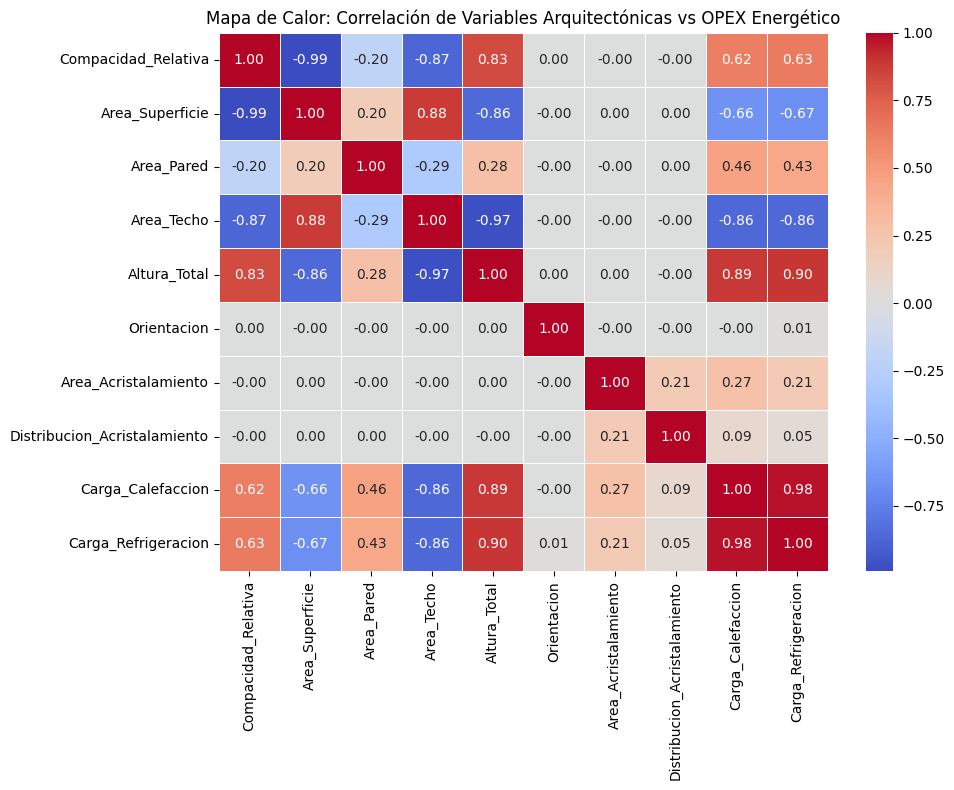

-> Visualización generada: Observamos alta correlación entre 'Altura_Total' y 'Carga_Calefaccion'.

Pipeline completado. Archivos 'dataset_original.csv' y 'dataset_estandarizado.csv' listos para MLflow.


In [1]:
# ==============================================================================
# SCRIPT: datos_prep.py (Fase 1 MLOps - Facility Management BBVA)
# Objetivo: Ingesta, limpieza, estandarización y análisis exploratorio (EDA)
# ==============================================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import os

print("Iniciando pipeline de preparación de datos...")

# 1. INGESTA DE DATOS (Dataset público UCI: Eficiencia Energética de Edificios)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00242/ENB2012_data.xlsx"
df = pd.read_excel(url)

# Renombrar columnas a un diccionario de datos legible (Criterio de Rúbrica)
df.columns = ['Compacidad_Relativa', 'Area_Superficie', 'Area_Pared', 'Area_Techo',
              'Altura_Total', 'Orientacion', 'Area_Acristalamiento',
              'Distribucion_Acristalamiento', 'Carga_Calefaccion', 'Carga_Refrigeracion']

# 2. LIMPIEZA Y DEDUPLICACIÓN
# Verificar nulos
nulos = df.isnull().sum().sum()
print(f"-> Valores nulos detectados: {nulos}")

# Eliminar duplicados
registros_iniciales = len(df)
df = df.drop_duplicates()
registros_finales = len(df)
print(f"-> Registros duplicados eliminados: {registros_iniciales - registros_finales}")

# 3. VISUALIZACIÓN DE PATRONES (Detección de anomalías)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Mapa de Calor: Correlación de Variables Arquitectónicas vs OPEX Energético")
plt.tight_layout()
plt.show()

print("-> Visualización generada: Observamos alta correlación entre 'Altura_Total' y 'Carga_Calefaccion'.")

# 4. ESTANDARIZACIÓN (Escalado de variables para los algoritmos ML)
scaler = StandardScaler()

# Separamos las variables predictoras (X) de nuestros objetivos de negocio (Y)
X = df.drop(columns=['Carga_Calefaccion', 'Carga_Refrigeracion'])
Y = df[['Carga_Calefaccion', 'Carga_Refrigeracion']]

# Aplicamos StandardScaler
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Reconstruimos el dataset limpio
df_limpio = pd.concat([X_scaled, Y.reset_index(drop=True)], axis=1)

# 5. EXPORTACIÓN DE ARTEFACTOS (Para versionado en GitHub)
os.makedirs("datos_limp", exist_ok=True)
os.makedirs("datos_ini", exist_ok=True)

df.to_csv("datos_ini/dataset_original.csv", index=False)
df_limpio.to_csv("datos_limp/dataset_estandarizado.csv", index=False)

print("\nPipeline completado. Archivos 'dataset_original.csv' y 'dataset_estandarizado.csv' listos para MLflow.")

In [5]:
# Instalar dependencias necesarias silenciosamente
!pip install mlflow xgboost scikit-learn -q

import pandas as pd
import mlflow
import mlflow.sklearn
import mlflow.xgboost
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

# 1. Cargar el dataset limpio
df = pd.read_csv("datos_limp/dataset_estandarizado.csv")
X = df.drop(columns=['Carga_Calefaccion', 'Carga_Refrigeracion'])
y = df['Carga_Calefaccion'] # Predeciremos el OPEX de Calefacción

# División Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Configuración del Tracking Server de MLflow (MIGRADO A SQLITE)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Optimizacion_OPEX_HVAC")

def evaluar_metricas(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

print("Iniciando entrenamiento y validación cruzada (Grid Search) con MLflow...\n")

# --- MODELO 1: Random Forest Regressor ---
with mlflow.start_run(run_name="RandomForest_GridSearch"):
    rf = RandomForestRegressor(random_state=42)
    # Hiperparámetros a evaluar
    parametros_rf = {'n_estimators': [50, 100], 'max_depth': [5, 10]}

    # Grid Search con 3-Fold Cross Validation
    grid_rf = GridSearchCV(rf, parametros_rf, cv=3, scoring='neg_mean_squared_error')
    grid_rf.fit(X_train, y_train)

    mejor_rf = grid_rf.best_estimator_
    y_pred_rf = mejor_rf.predict(X_test)
    mae_rf, rmse_rf, r2_rf = evaluar_metricas(y_test, y_pred_rf)

    # Registrar en MLflow
    mlflow.log_params(grid_rf.best_params_)
    mlflow.log_metrics({"MAE": mae_rf, "RMSE": rmse_rf, "R2": r2_rf})

    # [CORRECCIÓN APLICADA A CONTINUACIÓN]: Forzamos el formato 'pickle' para evitar el error de skops
    mlflow.sklearn.log_model(mejor_rf, "modelo_rf", serialization_format="pickle")

    print(f"[X] Random Forest completado -> R2: {r2_rf:.4f} | Mejores hiperparámetros: {grid_rf.best_params_}")

# --- MODELO 2: XGBoost Regressor ---
with mlflow.start_run(run_name="XGBoost_GridSearch"):
    xgb = XGBRegressor(random_state=42, objective='reg:squarederror')
    # Hiperparámetros a evaluar
    parametros_xgb = {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1]}

    # Grid Search con 3-Fold Cross Validation
    grid_xgb = GridSearchCV(xgb, parametros_xgb, cv=3, scoring='neg_mean_squared_error')
    grid_xgb.fit(X_train, y_train)

    mejor_xgb = grid_xgb.best_estimator_
    y_pred_xgb = mejor_xgb.predict(X_test)
    mae_xgb, rmse_xgb, r2_xgb = evaluar_metricas(y_test, y_pred_xgb)

    # Registrar en MLflow
    mlflow.log_params(grid_xgb.best_params_)
    mlflow.log_metrics({"MAE": mae_xgb, "RMSE": rmse_xgb, "R2": r2_xgb})
    mlflow.xgboost.log_model(mejor_xgb, "modelo_xgb")

    print(f"[X] XGBoost completado       -> R2: {r2_xgb:.4f} | Mejores hiperparámetros: {grid_xgb.best_params_}")

print("\n¡Ejecución de MLOps exitosa! Todos los artefactos están guardados en MLflow (Base de datos SQLite).")

Iniciando entrenamiento y validación cruzada (Grid Search) con MLflow...



2026/10/26 04:46:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 04:46:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


[X] Random Forest completado -> R2: 0.9976 | Mejores hiperparámetros: {'max_depth': 10, 'n_estimators': 100}


2026/10/26 04:46:34 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


[X] XGBoost completado       -> R2: 0.9984 | Mejores hiperparámetros: {'learning_rate': 0.1, 'n_estimators': 100}

¡Ejecución de MLOps exitosa! Todos los artefactos están guardados en MLflow (Base de datos SQLite).


In [11]:
import mlflow
import pandas as pd

# Apuntamos a nuestra base de datos local de MLflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Consultamos los experimentos registrados usando la API oficial
df_runs = mlflow.search_runs(experiment_names=["Optimizacion_OPEX_HVAC"])

# Filtramos las columnas clave para mostrar los resultados de forma limpia
columnas_visibles = [c for c in df_runs.columns if 'run_name' in c or 'metrics.' in c or 'params.' in c]
df_evidencia = df_runs[columnas_visibles]

print("=== TABLA DE EVIDENCIA DE MLFLOW ===")
display(df_evidencia)

=== TABLA DE EVIDENCIA DE MLFLOW ===


,metrics.R2,metrics.RMSE,metrics.MAE,params.learning_rate,params.n_estimators,params.max_depth
0,0.998413,0.406653,0.287887,0.1,100,None
1,0.997628,0.497242,0.354427,None,100,10
2,0.997628,0.497242,0.354427,None,100,10


In [13]:
# Habilitamos las tablas interactivas nativas de Colab (no requieren credenciales de Google Sheets)
from google.colab import data_table

# Mostramos el DataFrame de forma interactiva
data_table.enable_dataframe_formatter()
display(df_evidencia)

,metrics.R2,metrics.RMSE,metrics.MAE,params.learning_rate,params.n_estimators,params.max_depth
0,0.998413,0.406653,0.287887,0.1,100,None
1,0.997628,0.497242,0.354427,None,100,10
2,0.997628,0.497242,0.354427,None,100,10


In [14]:
# 1. Volver a consultar los datos de MLflow con mayor detalle
df_runs_detallado = mlflow.search_runs(experiment_names=["Optimizacion_OPEX_HVAC"])

# 2. Seleccionar columnas clave y renombrarlas de forma comprensible
columnas_origen = [
    'tags.mlflow.runName',
    'metrics.R2',
    'metrics.RMSE',
    'metrics.MAE',
    'params.n_estimators',
    'params.max_depth',
    'params.learning_rate'
]

# Filtrar únicamente las columnas que existen en el DataFrame resultante
columnas_validas = [col for col in columnas_origen if col in df_runs_detallado.columns]
df_presentacion = df_runs_detallado[columnas_validas].copy()

# Renombrar columnas para la visualización del usuario
renombrar_dict = {
    'tags.mlflow.runName': 'Modelo (Run Name)',
    'metrics.R2': 'R² (Precisión)',
    'metrics.RMSE': 'RMSE (Error Cuadrático)',
    'metrics.MAE': 'MAE (Error Absoluto)',
    'params.n_estimators': 'Estimadores (n_estimators)',
    'params.max_depth': 'Profundidad Máxima (max_depth)',
    'params.learning_rate': 'Tasa de Aprendizaje (learning_rate)'
}
df_presentacion = df_presentacion.rename(columns=renombrar_dict)

# 3. Formatear métricas numéricas a 4 decimales para mayor legibilidad
columnas_metricas = ['R² (Precisión)', 'RMSE (Error Cuadrático)', 'MAE (Error Absoluto)']
for col in columnas_metricas:
    if col in df_presentacion.columns:
        df_presentacion[col] = df_presentacion[col].round(4)

# Rellenar valores nulos de los parámetros ausentes con "-" para limpieza visual
columnas_params = ['Estimadores (n_estimators)', 'Profundidad Máxima (max_depth)', 'Tasa de Aprendizaje (learning_rate)']
for col in columnas_params:
    if col in df_presentacion.columns:
        df_presentacion[col] = df_presentacion[col].fillna('-')

# 4. Mostrar la tabla formateada interactivamente
print("=== COMPARATIVA DETALLADA DE MODELOS EN MLFLOW ===")
display(df_presentacion)

=== COMPARATIVA DETALLADA DE MODELOS EN MLFLOW ===


,Modelo (Run Name),R² (Precisión),RMSE (Error Cuadrático),MAE (Error Absoluto),Estimadores (n_estimators),Profundidad Máxima (max_depth),Tasa de Aprendizaje (learning_rate)
0,XGBoost_GridSearch,0.9984,0.4067,0.2879,100,-,0.1
1,RandomForest_GridSearch,0.9976,0.4972,0.3544,100,10,-
2,RandomForest_GridSearch,0.9976,0.4972,0.3544,100,10,-
